# matplotlib

`px.Plot` draws with matplotlib by default and returns the matplotlib Axes, so titles, panels, annotations and saving
work as in any other matplotlib figure. Passing an Axes as `ax` draws into it, which puts several objects into one
figure or into the panels of `plt.subplots`. Besides faces, shapes, wires, compounds and sketches, `Plot` takes
selections, ids such as `"Sketch.1"`, and OpenCASCADE shapes.

The example on this page is a bell crank: a pivot boss of radius 9 and two arms, 40 and 30 long, that end in bosses
of radius 6, with a hole in each boss. Each arm is a line offset by 4, which gives a band of width 8 with round ends.

In [1]:
import matplotlib.pyplot as plt
import planex as px

bosses = [px.Circle((0, 0), 9).Face(), px.Circle((40, 0), 6).Face(), px.Circle((0, 30), 6).Face()]
arms = [px.Line((0, 0), (40, 0)).Offset(4), px.Line((0, 0), (0, 30)).Offset(4)]
holes = [px.Circle((0, 0), 4).Face(), px.Circle((40, 0), 3).Face(), px.Circle((0, 30), 3).Face()]
crank = px.Subtract([px.Unify(bosses + arms), *holes])

## Two positions in one figure

The example draws the bell crank at rest and swung by 30° about its pivot. The second call draws into the Axes that
the first call returned, and each position gets its own fill color.

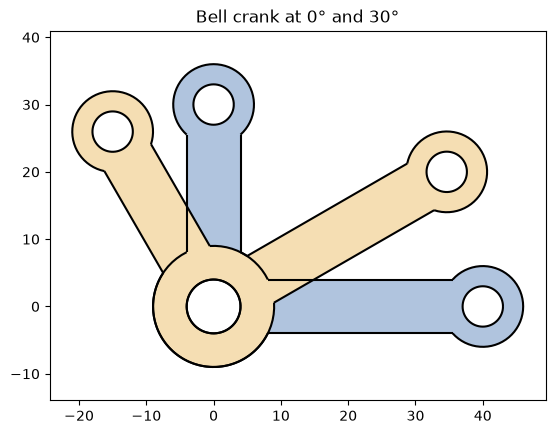

In [2]:
ax = crank.Plot(face_col="lightsteelblue", legend=False)
crank.Rotated((0, 0), 30).Plot(ax=ax, face_col="wheat", legend=False)
ax.set_title("Bell crank at 0° and 30°");

## Panels: before and after fitting arcs

With `line_col="type"`, lines are drawn in black, arcs in orange and splines in green, each with a legend entry. This
shows what a defeaturing step did. The example is a slot as it might come from a tessellated export: the exact slot,
of width 2 along a spine of 4, is turned into a polygon with `Polylines`, and `FromPolyline` makes a wire of short
lines from it. `FitArcs` turns the short lines back into the slot's two lines and two arcs. The two panels of
`plt.subplots` show the polygon and the fitted slot side by side.

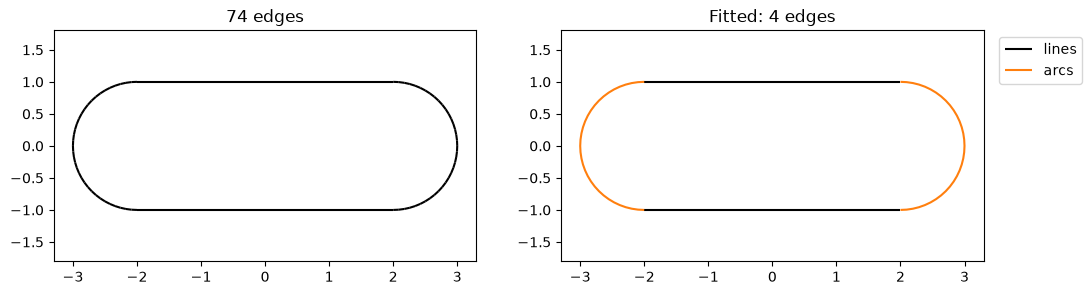

In [3]:
exact = px.QuickSketch((-2, 0)).Slot(4, 2).Face()
slot = px.Face([px.FromPolyline(exact.Polylines(1e-3)[0], closed=True)])
fitted = slot.Copy().FitArcs(tol=1e-4, max_edge_length=0.2)

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 3))
slot.Plot(ax=left, line_col="type", face_col=None, legend=False)
fitted.Plot(ax=right, line_col="type", face_col=None)
left.set_title(f"{len(slot.edges)} edges")
right.set_title(f"Fitted: {len(fitted.edges)} edges");

See [Fitting arcs](../defeaturing/arcs.md) for the fit and its tolerance.

## A section through a solid

With a plane as the second argument, `px.Plot` draws the section of an OpenCASCADE shape in that plane. The example
is a block of 60 × 40 × 20 with a bore of diameter 16 and a step milled into one end, cut at half its height.
`px.Intersect3d` returns the same section as a planex2d shape, for measuring it or for further Boolean operations.

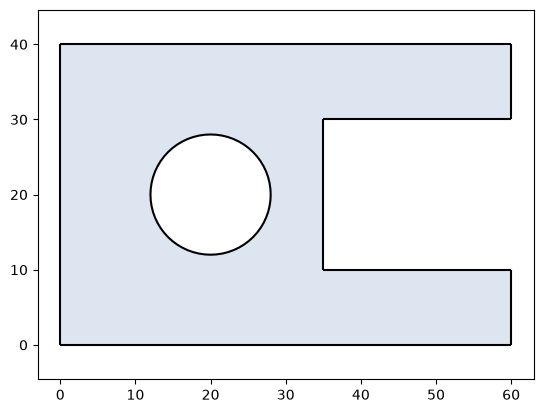

In [4]:
import netgen.occ as occ

block = occ.Box(occ.Pnt(0, 0, 0), occ.Pnt(60, 40, 20)) - occ.Cylinder(occ.Pnt(20, 20, 0), occ.Z, 8, 20)
block = block - occ.Box(occ.Pnt(35, 10, 8), occ.Pnt(60, 30, 20))
px.Plot(block, px.XY.Offset(10));

## The look of these docs

The figures in this documentation are drawn the same way, with one color for every edge, a light fill and no axes:

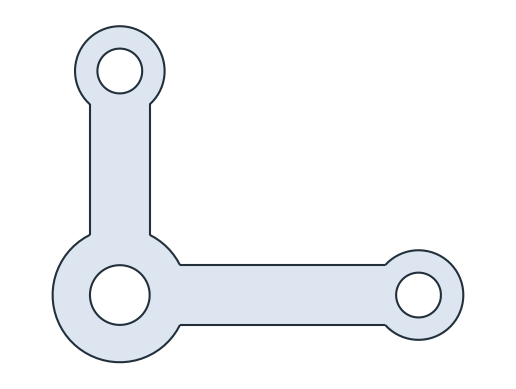

In [5]:
ax = crank.Plot(line_col="#22303c", face_col="#dde6f0")
ax.axis("off");

## Saving

`ax.figure` is the matplotlib figure, so it is saved as any other:

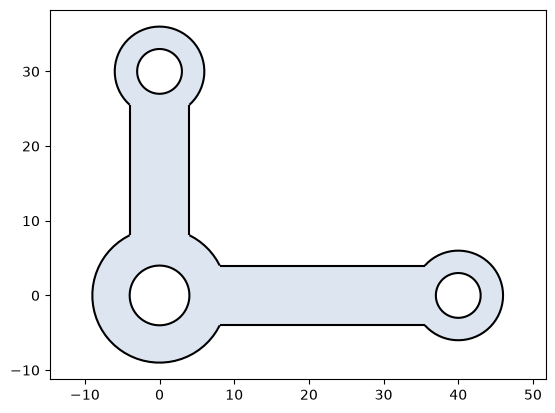

In [6]:
ax = crank.Plot()
ax.figure.savefig("bell-crank.png", dpi=200)